<a href="https://colab.research.google.com/github/tantg88888/secops-automation-demo/blob/main/notebooks/02_account_security_review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Regular account security review (Active Directory + Entra ID)

**Problem.** Every review cycle, the security team receives two exports: on-premises Active Directory users and cloud (Entra ID / Microsoft 365) accounts. Analysts reconciled them by hand against a criteria checklist, then emailed each department head a list of accounts to confirm or disable.

**What was automated.** The review is started from an agent; workflows merge the two reports, apply the criteria and produce a master tracker plus one information sheet per department head. This notebook reproduces the logic in Python on **synthetic data** (fictitious `corp.example.com`).

**Data problems reproduced from real exports**
* AD dates are stored **day-first**, so a month-first parser silently swaps day and month (or fails).
* Manager *names* are masked in the AD export, so routing must use manager **email**.
* Some accounts exist in only one of the two systems.
* `ServiceAccount` is blank instead of "No".

In [7]:
import os
REPO = "https://github.com/tantg88888/secops-automation-demo"
if not os.path.exists("data"):
    if not os.path.exists("secops-automation-demo"):
        os.system(f"git clone -q {REPO}")
    os.chdir("secops-automation-demo")

import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("images", exist_ok=True)
os.makedirs("output", exist_ok=True)

ad    = pd.read_csv("data/ad_users_onprem.csv")
entra = pd.read_csv("data/entra_accounts.csv")
REVIEW_DATE = pd.Timestamp("2026-09-21")
print(f"AD {len(ad)} users | Entra {len(entra)} accounts")
ad.head(3)

AD 200 users | Entra 212 accounts


,UserPrincipalName,DisplayName,Department,Company,ManagerName,ManagerEmail,Enabled,ServiceAccount,PrivilegedGroups,WhenCreated,LastLogonDate,PasswordNeverExpires
0,yusof.ho1@corp.example.com,Yusof Ho,IT,EIG-GEN,XXXXX XXXXX,oliver.lee2@corp.example.com,True,NaN,NaN,02/09/2022,21/09/2026,False
1,oliver.lee2@corp.example.com,Oliver Lee,Finance,EIG-LIFE,XXXXX XXXXX,meiling.singh3@corp.example.com,True,NaN,NaN,11/12/2021,NaN,False
2,meiling.singh3@corp.example.com,Mei Ling Singh,IT,EIG-SG,XXXXX XXXXX,ben.ong10@corp.example.com,True,NaN,NaN,13/02/2019,21/09/2026,False


## 1 · Fix the day-first dates

In [8]:
wrong = pd.to_datetime(ad["WhenCreated"], format="%m/%d/%Y", errors="coerce")
right = pd.to_datetime(ad["WhenCreated"], format="%d/%m/%Y", errors="coerce")
print(f"Month-first parse: {wrong.isna().sum()} rows fail, {(wrong.notna() & (wrong != right)).sum()} rows silently get the wrong date")
ad["WhenCreated"]   = right
ad["LastLogonDate"] = pd.to_datetime(ad["LastLogonDate"], format="%d/%m/%Y", errors="coerce")
for col in ["createdDateTime", "lastSignInDateTime"]:
    entra[col] = pd.to_datetime(entra[col], utc=True, errors="coerce").dt.tz_localize(None)

Month-first parse: 129 rows fail, 63 rows silently get the wrong date


## 2 · Merge on UPN (population = union of both systems)

In [9]:
ad["upn"], entra["upn"] = ad["UserPrincipalName"].str.lower(), entra["userPrincipalName"].str.lower()
acc = ad.merge(entra, on="upn", how="outer", indicator="source")
acc["source"] = acc["source"].map({"both": "AD + Entra", "left_only": "AD only", "right_only": "Entra only"})
acc["display_name"] = acc["DisplayName"].fillna(acc["displayName"])
acc["enabled"] = acc["Enabled"].fillna(acc["accountEnabled"]).astype(bool)
acc["is_service"] = acc["ServiceAccount"].fillna("No").eq("Yes")          # blank means No
acc["last_activity"] = acc[["LastLogonDate", "lastSignInDateTime"]].max(axis=1)
acc["Department"] = acc["Department"].fillna("Cloud-only (no AD record)")
acc["source"].value_counts()

/tmp/ipykernel_5837/2669632433.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  acc["enabled"] = acc["Enabled"].fillna(acc["accountEnabled"]).astype(bool)


,count
source,
AD + Entra,192
Entra only,20
AD only,8


## 3 · Review criteria
In production the criteria live in a workbook the security team maintains; here they are a list of rules.

In [10]:
inactive_days = (REVIEW_DATE - acc["last_activity"]).dt.days
RULES = {
    "C1 Inactive > 90 days":         acc.enabled & (inactive_days > 90),
    "C2 Enabled, never signed in":   acc.enabled & acc["last_activity"].isna(),
    "C3 Privileged group member":    acc["PrivilegedGroups"].notna(),
    "C4 Cloud-only / guest account": acc["source"].eq("Entra only") & acc.enabled,
    "C5 No MFA registered":          acc.enabled & acc["mfaRegistered"].eq(False) & ~acc.is_service,
    "C6 Password never expires":     acc["PasswordNeverExpires"].eq(True) & ~acc.is_service,
}
for name, mask in RULES.items():
    acc[name] = mask.fillna(False).astype(bool)
rule_cols = list(RULES)
acc["findings"] = acc[rule_cols].apply(lambda r: "; ".join(c for c in rule_cols if r[c]), axis=1)
flagged = acc[acc["findings"] != ""].copy()

# Domain admins go to the infrastructure provider; everyone else to their manager
flagged["route_to"] = flagged["PrivilegedGroups"].eq("Domain Admins").map({True: "Infrastructure provider", False: None})
flagged["route_to"] = flagged["route_to"].fillna(flagged["ManagerEmail"]).fillna("Security team (no manager)")
print(f"{len(flagged)} of {len(acc)} accounts need review")
acc[rule_cols].sum().sort_values()

97 of 220 accounts need review


,0
C6 Password never expires,4
C4 Cloud-only / guest account,18
C5 No MFA registered,20
C3 Privileged group member,24
C1 Inactive > 90 days,29
"C2 Enabled, never signed in",32


## 4 · Dashboard

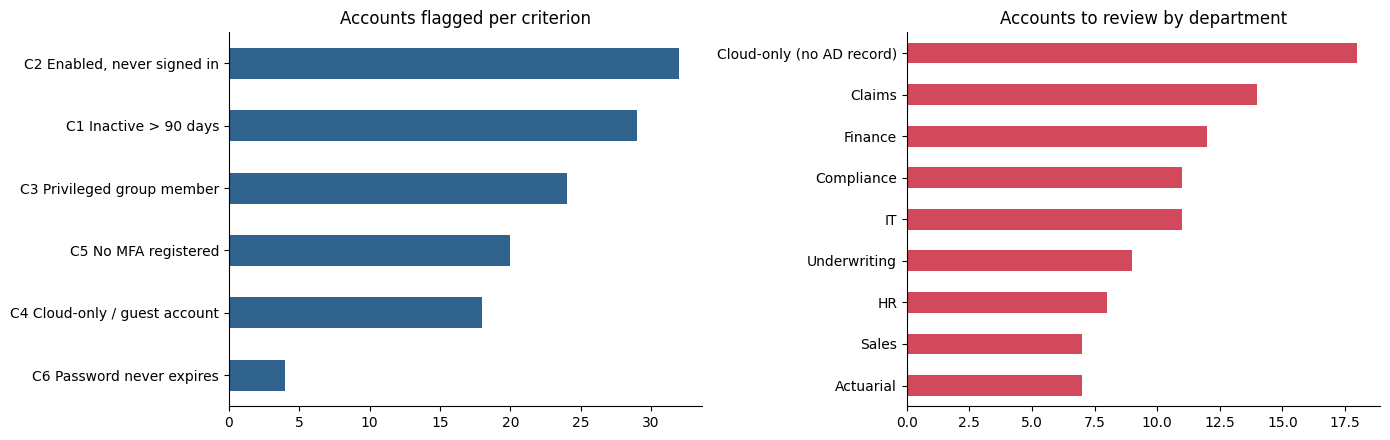

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
acc[rule_cols].sum().sort_values().plot.barh(ax=axes[0], color="#30638E")
axes[0].set_title("Accounts flagged per criterion")
flagged.groupby("Department").size().sort_values().plot.barh(ax=axes[1], color="#D1495B")
axes[1].set_title("Accounts to review by department")
for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("images/account_review_dashboard.png", dpi=150); plt.show()

## 5 · Outputs: master tracker + one sheet per reviewer

In [12]:
cols = ["upn", "display_name", "Department", "source", "enabled", "last_activity", "findings", "route_to"]
with pd.ExcelWriter("output/account_review_master.xlsx") as xw:
    flagged[cols].to_excel(xw, sheet_name="Master", index=False)
    for i, (who, grp) in enumerate(flagged.groupby("route_to")):
        grp[cols].to_excel(xw, sheet_name=f"R{i+1:02d}", index=False)
print("Saved output/account_review_master.xlsx")
flagged[cols].head(10)

Saved output/account_review_master.xlsx


,upn,display_name,Department,source,enabled,last_activity,findings,route_to
3,alex.rahman133@corp.example.com,Alex Rahman,Finance,AD + Entra,True,2026-09-21,C6 Password never expires,vivian.chen8@corp.example.com
5,alex.tan96@corp.example.com,Alex Tan,Claims,AD + Entra,True,2025-08-17,C1 Inactive > 90 days,vivian.chen8@corp.example.com
6,alex.teo203@corp.example.com,Alex Teo,Cloud-only (no AD record),Entra only,True,NaT,"C2 Enabled, never signed in; C4 Cloud-only / g...",Security team (no manager)
9,ben.ho46@corp.example.com,Ben Ho,Sales,AD + Entra,True,2025-08-19,C1 Inactive > 90 days,priya.ong15@corp.example.com
15,ben.tan140@corp.example.com,Ben Tan,HR,AD + Entra,True,NaT,"C2 Enabled, never signed in",ben.ong10@corp.example.com
16,ben.teo45@corp.example.com,Ben Teo,Claims,AD + Entra,True,2025-08-17,C1 Inactive > 90 days; C5 No MFA registered,daniel.singh14@corp.example.com
21,chloe.lee121@corp.example.com,Chloe Lee,Underwriting,AD + Entra,True,2026-09-21,C3 Privileged group member,huimin.lee6@corp.example.com
22,chloe.lee65@corp.example.com,Chloe Lee,Finance,AD + Entra,True,2026-09-21,C6 Password never expires,ben.wong7@corp.example.com
24,chloe.ng116@corp.example.com,Chloe Ng,IT,AD + Entra,True,2026-09-21,C3 Privileged group member,Infrastructure provider
27,chloe.singh114@corp.example.com,Chloe Singh,Compliance,AD + Entra,True,2025-08-18,C1 Inactive > 90 days,vivian.chen8@corp.example.com
